# Kaggle Challenge：EDA

This notebook performs a systematic examination of `train.csv` using **pandas, NumPy, Matplotlib, and Seaborn**. It begins by assessing the data structure and quality, then proceeds to analyze missing values, the target variable `buy`, the relationship between users and concerts, numerical and categorical features, geographical distances, outliers, and validation strategies for modeling. Since the five rows associated with each user are interdependent, the training/validation split must be performed by grouping the data according to `user_id`.

**How ​​to run:** Place this notebook in the same folder as `train.csv` before executing it.

In [10]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 50)
pd.set_option("display.width", 100)
pd.set_option("display.max_colwidth", 50)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")

# Current directory
train_path = Path("train.csv")
df = pd.read_csv(train_path)
print(f"doc_path：{train_path.resolve()}")
print(f"data_shape：{df.shape[0]:,} rows × {df.shape[1]} columns")
# First 5 rows
display(df.head())
print(df.columns)

doc_path：C:\Users\86135\Kaggle Challenge\train.csv
data_shape：30,000 rows × 32 columns


,row_id,user_id,music_app_user_id,age,education,spending_capacity_band,home_city,home_lat,home_lon,stated_favourite_genre,past_purchase_count,first_timer,typical_ticket_spend,usual_booking_lead_days,concert_id,artist_id,artist_name,genres,venue_city,venue_lat,venue_lon,concert_at,sale_opened_at,prediction_at,ticket_price,booking_fee,discount_pct,event_page_visits_7d,wishlisted,travel_search_city,travel_search_arrival,buy
0,R2F019957,U2CFDCAAD,M1B01D2D7,23,postgraduate,2,Nantes,47.218,-1.554,pop,5,0,144.33,31.0,C04,A04,Tame Impala,pop|alternative|electronic|psychedelic,Lille,50.630,3.057,2026-12-12T20:00:00Z,2026-09-28T00:00:00Z,2026-10-01T00:00:00Z,75.0,9.50,0,0.0,1,NaN,NaN,0
1,R0804D93A,U1FC01010,M1B2C63CC,51,undergraduate,5,Bordeaux,44.838,-0.579,pop,0,1,NaN,NaN,C02,A02,Olivia Rodrigo,pop|pop_rock|alternative,Lyon,45.764,4.835,2026-11-10T20:00:00Z,2026-09-28T00:00:00Z,2026-10-01T00:00:00Z,85.0,10.10,0,3.0,0,NaN,NaN,1
2,R367FE81E,U0C605712,M3AEF638D,32,secondary,1,Lyon,45.764,4.835,classical,1,0,90.12,36.0,C03,A03,Taylor Swift,pop|pop_rock|alternative|folk_country,Bordeaux,44.838,-0.579,2026-11-26T20:00:00Z,2026-09-28T00:00:00Z,2026-10-01T00:00:00Z,175.0,15.50,20,1.0,1,NaN,NaN,0
3,R344BBE29,U25D1DD8A,M00C580ED,24,secondary,2,Paris,48.857,2.352,jazz_funk,8,0,115.32,20.0,C01,A01,Kendrick Lamar,hip_hop|rnb_soul|jazz_funk|pop,Paris,48.857,2.352,2026-10-25T20:00:00Z,2026-09-28T00:00:00Z,2026-10-01T00:00:00Z,84.0,10.04,0,1.0,1,NaN,NaN,1
4,R004ABDEB,U1600BC92,M29AC37E6,21,secondary,3,Bordeaux,44.838,-0.579,NaN,0,1,NaN,NaN,C05,A05,SZA,hip_hop|rnb_soul|jazz_funk|pop|alternative,Nantes,47.218,-1.554,2026-12-28T20:00:00Z,2026-09-28T00:00:00Z,2026-10-01T00:00:00Z,95.0,10.70,0,0.0,0,Rennes,2026-12-28,1


Index(['row_id', 'user_id', 'music_app_user_id', 'age', 'education', 'spending_capacity_band',
       'home_city', 'home_lat', 'home_lon', 'stated_favourite_genre', 'past_purchase_count',
       'first_timer', 'typical_ticket_spend', 'usual_booking_lead_days', 'concert_id', 'artist_id',
       'artist_name', 'genres', 'venue_city', 'venue_lat', 'venue_lon', 'concert_at',
       'sale_opened_at', 'prediction_at', 'ticket_price', 'booking_fee', 'discount_pct',
       'event_page_visits_7d', 'wishlisted', 'travel_search_city', 'travel_search_arrival', 'buy'],
      dtype='object')


## 1.General

In [11]:
print("column_name_list：")
print(df.columns.tolist())
print("\ndatatype：")
display(df.dtypes.rename("dtype").to_frame())
print("\ninformation：")
df.info()

checks = {
    "row_id duplicated?": df["row_id"].duplicated().sum() if "row_id" in df else None,
    "user_id none?": df["user_id"].isna().sum() if "user_id" in df else None,
    "user_id + concert_id duplicated?": df.duplicated(["user_id", "concert_id"]).sum()
        if {"user_id", "concert_id"}.issubset(df.columns) else None,
    "Howmany_Users": df["user_id"].nunique() if "user_id" in df else None,
    "Howmany_Concerts": df["concert_id"].nunique() if "concert_id" in df else None,
}
display(pd.Series(checks, name="result").to_frame())

if "user_id" in df and "concert_id" in df:
    concerts_per_user = df.groupby("user_id")["concert_id"].nunique()
    display(concerts_per_user.value_counts().sort_index().rename_axis("concerts_per_user").to_frame("Users"))
    display(df.groupby("concert_id").agg(
        rows=("row_id", "size"), users=("user_id", "nunique")
    ).sort_index())

column_name_list：
['row_id', 'user_id', 'music_app_user_id', 'age', 'education', 'spending_capacity_band', 'home_city', 'home_lat', 'home_lon', 'stated_favourite_genre', 'past_purchase_count', 'first_timer', 'typical_ticket_spend', 'usual_booking_lead_days', 'concert_id', 'artist_id', 'artist_name', 'genres', 'venue_city', 'venue_lat', 'venue_lon', 'concert_at', 'sale_opened_at', 'prediction_at', 'ticket_price', 'booking_fee', 'discount_pct', 'event_page_visits_7d', 'wishlisted', 'travel_search_city', 'travel_search_arrival', 'buy']

datatype：


,dtype
row_id,object
user_id,object
music_app_user_id,object
age,int64
education,object
spending_capacity_band,int64
home_city,object
home_lat,float64
home_lon,float64
stated_favourite_genre,object



information：
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   row_id                   30000 non-null  object 
 1   user_id                  30000 non-null  object 
 2   music_app_user_id        28305 non-null  object 
 3   age                      30000 non-null  int64  
 4   education                30000 non-null  object 
 5   spending_capacity_band   30000 non-null  int64  
 6   home_city                30000 non-null  object 
 7   home_lat                 30000 non-null  float64
 8   home_lon                 30000 non-null  float64
 9   stated_favourite_genre   25375 non-null  object 
 10  past_purchase_count      30000 non-null  int64  
 11  first_timer              30000 non-null  int64  
 12  typical_ticket_spend     21760 non-null  float64
 13  usual_booking_lead_days  21760 non-null  float64
 14  concert_

,result
row_id duplicated?,0
user_id none?,0
user_id + concert_id duplicated?,0
Howmany_Users,6000
Howmany_Concerts,5


,Users
concerts_per_user,
5,6000


,rows,users
concert_id,,
C01,6000,6000
C02,6000,6000
C03,6000,6000
C04,6000,6000
C05,6000,6000


## 2.Date

Dates are currently typically read in as strings. Once converted to `datetime` objects, they can be used to calculate features such as "number of days until the performance."

In [13]:
date_cols = [c for c in ["concert_at", "sale_opened_at", "prediction_at", "travel_search_arrival"] if c in df]
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors="coerce", utc=True)

print("Date column data types after conversion:")
display(df[date_cols].dtypes.to_frame("dtype"))
print("Valid value ranges for date fields:")
for col in date_cols:
    print(f"{col}: {df[col].min()} → {df[col].max()} | null {df[col].isna().sum():,}")

Date column data types after conversion:


,dtype
concert_at,"datetime64[ns, UTC]"
sale_opened_at,"datetime64[ns, UTC]"
prediction_at,"datetime64[ns, UTC]"
travel_search_arrival,"datetime64[ns, UTC]"


Valid value ranges for date fields:
concert_at: 2026-10-25 20:00:00+00:00 → 2026-12-28 20:00:00+00:00 | null 0
sale_opened_at: 2026-09-28 00:00:00+00:00 → 2026-09-28 00:00:00+00:00 | null 0
prediction_at: 2026-10-01 00:00:00+00:00 → 2026-10-01 00:00:00+00:00 | null 0
travel_search_arrival: 2026-10-07 00:00:00+00:00 → 2027-01-15 00:00:00+00:00 | null 22,496


## 3. Missing Values
T the absence of historical spending data or "days in advance" booking information for first-time purchasers represent**structural missingne**. Similarly, a lack of travel search data may simply mean the user has no search history, while an unlinked music account does not necessarily imply an absence of musical preferences. Begin by calculating the number of missing values ​​for each column, then examine whether these missing values ​​are concentrated within specific user segments or categories.

,missing_count,missing_pct,dtype
travel_search_city,22496,74.99%,object
travel_search_arrival,22496,74.99%,"datetime64[ns, UTC]"
typical_ticket_spend,8240,27.47%,float64
usual_booking_lead_days,8240,27.47%,float64
stated_favourite_genre,4625,15.42%,object
music_app_user_id,1695,5.65%,object
event_page_visits_7d,863,2.88%,float64


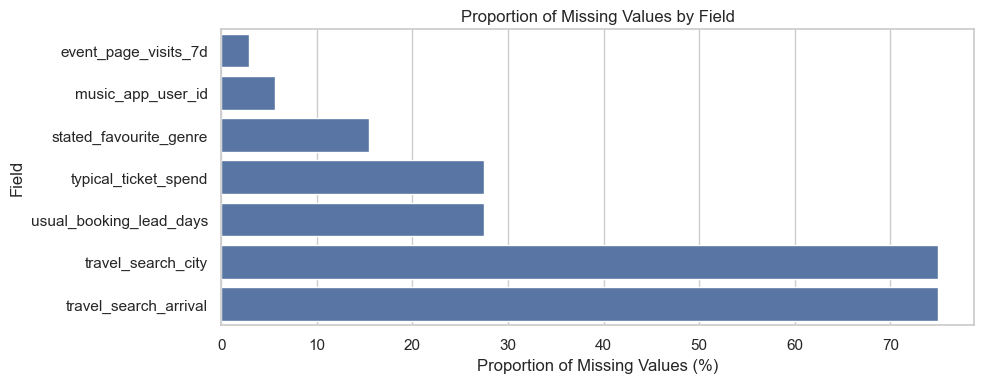

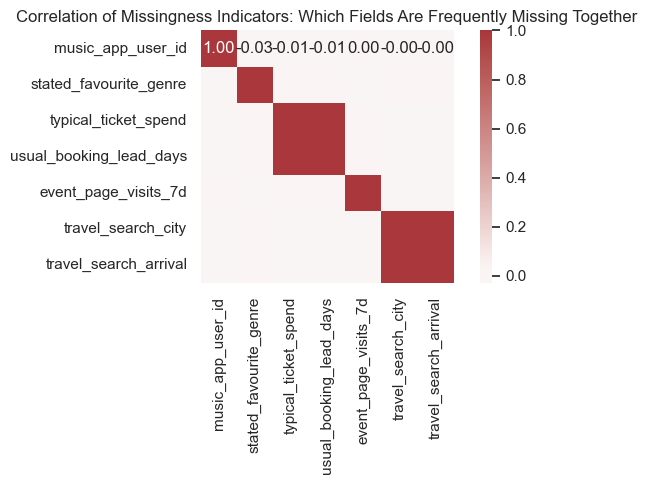

,buy=0,buy=1
music_app_user_id,4.31%,8.30%
stated_favourite_genre,15.20%,15.85%
typical_ticket_spend,26.20%,29.97%
usual_booking_lead_days,26.20%,29.97%
event_page_visits_7d,3.00%,2.64%
travel_search_city,76.76%,71.49%
travel_search_arrival,76.76%,71.49%


In [16]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": df.isna().mean().mul(100),
    "dtype": df.dtypes.astype(str),
})
missing = missing.query("missing_count > 0").sort_values("missing_pct", ascending=False)
display(missing.style.format({"missing_pct": "{:.2f}%"}))

if not missing.empty:
    plt.figure(figsize=(10, max(4, 0.38 * len(missing))))
    plot_data = missing.sort_values("missing_pct")
    ax = sns.barplot(data=plot_data.reset_index(), x="missing_pct", y="index", color="#4C72B0")
    ax.set(title="Proportion of Missing Values ​​by Field", xlabel="Proportion of Missing Values ​​(%)", ylabel="Field")
    plt.tight_layout()
    plt.show()

# Co-occurrence of missingness indicators (sampled and plotted when the number of samples is large)
missing_cols = df.columns[df.isna().any()].tolist()
if missing_cols:
    sample_missing = df[missing_cols].isna().astype(int)
    plt.figure(figsize=(max(7, 0.6 * len(missing_cols)), max(5, 0.5 * len(missing_cols))))
    sns.heatmap(sample_missing.corr(), annot=True, fmt=".2f", cmap="vlag", center=0, square=True)
    plt.title("Correlation of Missingness Indicators: Which Fields Are Frequently Missing Together")
    plt.tight_layout()
    plt.show()

# Missingness rates grouped by target: Differences may suggest that the missingness itself carries predictive information, though this does not imply a causal relationship.if "buy" in df:
    miss_by_target = df.groupby("buy")[missing_cols].apply(lambda x: x.isna().mean()).T * 100
    if not miss_by_target.empty:
        miss_by_target.columns = [f"buy={c}" for c in miss_by_target.columns]
        display(miss_by_target.style.format("{:.2f}%"))

### Initial Assessment of Missing Value Handling

- Missing values ​​in `typical_ticket_spend` and `usual_booking_lead_days` are highly likely to correspond to cases where `first_timer=1`. This relationship should be verified first; if confirmed, retaining the missing values—while adding a flag for "is a first-time purchaser"—is generally more appropriate than simply imputing the mean.
- For missing `music_app_user_id` values, a `has_music_account` feature can be created. If music-listening JSON data becomes available later, it will be necessary to distinguish between "no account linked," "account linked but no listening activity," and "missing listening data file."
- Missing values ​​in `travel_search_city` or `travel_search_arrival` likely indicate that no travel searches were observed. A `has_travel_search` feature should be created; do not arbitrarily impute these with a specific city name.
- There are a small number of missing values ​​in `event_page_visits_7d`. First, clarify what these missing values ​​signify. You could create a missing-value indicator flag, and then consider imputation using the median or mode. For tree-based models, it may also be acceptable to simply leave these as `NaN`.

## 4. Completely Duplicate Rows, Constant Columns, and Unique Values

In [19]:
print("Number of completely duplicate rows:", df.duplicated().sum())
constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
print("A column with only one value: ", constant_cols)

unique_summary = pd.DataFrame({
    "n_unique": df.nunique(dropna=True),
    "unique_ratio": df.nunique(dropna=True) / len(df),
    "dtype": df.dtypes.astype(str),
}).sort_values("n_unique", ascending=False)
display(unique_summary)

Number of completely duplicate rows: 0
A column with only one value:  ['sale_opened_at', 'prediction_at']


,n_unique,unique_ratio,dtype
row_id,30000,1.000000,object
user_id,6000,0.200000,object
music_app_user_id,5661,0.188700,object
typical_ticket_spend,4078,0.135933,float64
usual_booking_lead_days,426,0.014200,float64
travel_search_arrival,93,0.003100,"datetime64[ns, UTC]"
age,48,0.001600,int64
ticket_price,15,0.000500,float64
booking_fee,15,0.000500,float64
past_purchase_count,14,0.000467,int64


## 5. Target Variable `buy`: Class Proportions and Baseline

,count,share
buy,,
0,19914,0.6638
1,10086,0.3362


Overall purchase rate：33.62%


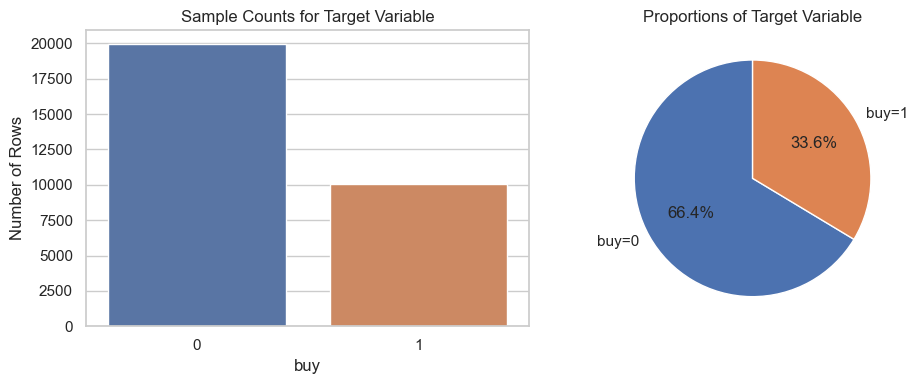

In [21]:
if "buy" in df:
    target_counts = df["buy"].value_counts(dropna=False).sort_index()
    target_rates = df["buy"].value_counts(normalize=True).sort_index()
    display(pd.DataFrame({"count": target_counts, "share": target_rates}).rename_axis("buy"))
    print(f"Overall purchase rate：{df['buy'].mean():.2%}")
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    sns.countplot(data=df, x="buy", ax=axes[0])
    axes[0].set_title("Sample Counts for Target Variable")
    axes[0].set_xlabel("buy")
    axes[0].set_ylabel("Number of Rows")
    axes[1].pie(target_counts.values, labels=[f"buy={i}" for i in target_counts.index], autopct="%1.1f%%", startangle=90)
    axes[1].set_title("Proportions of Target Variable")
    plt.tight_layout()
    plt.show()

## 6. Purchase Distribution: User-Level vs. Concert-Level

Since a single user may purchase tickets for multiple concerts, it is necessary to examine both the purchase rate for each individual concert and the number of concerts purchased per user.

,,rows,buyers,conversion_rate
concert_id,artist_name,,,
C03,Taylor Swift,6000,2329,38.82%
C05,SZA,6000,2188,36.47%
C01,Kendrick Lamar,6000,1975,32.92%
C02,Olivia Rodrigo,6000,1900,31.67%
C04,Tame Impala,6000,1694,28.23%


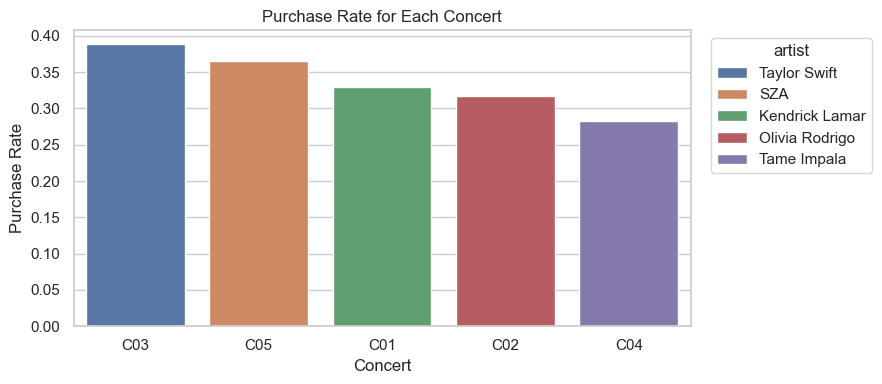

,Number of Users
Number of Concerts Purchased per User,
0,908
1,1909
2,1822
3,968
4,336
5,57


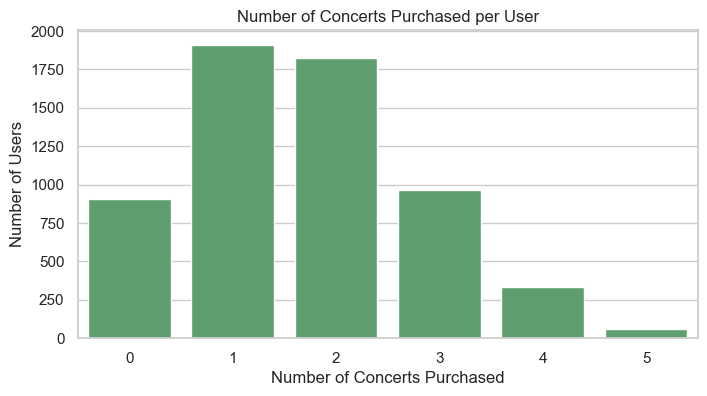

In [23]:
if {"concert_id", "buy"}.issubset(df.columns):
    concert_rates = df.groupby(["concert_id", "artist_name"], dropna=False).agg(
        rows=("buy", "size"), buyers=("buy", "sum"), conversion_rate=("buy", "mean")
    ).sort_values("conversion_rate", ascending=False)
    display(concert_rates.style.format({"conversion_rate": "{:.2%}"}))
    plt.figure(figsize=(9, 4))
    sns.barplot(data=concert_rates.reset_index(), x="concert_id", y="conversion_rate", hue="artist_name", dodge=False)
    plt.title("Purchase Rate for Each Concert")
    plt.ylabel("Purchase Rate")
    plt.xlabel("Concert")
    plt.legend(title="artist", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

if {"user_id", "buy"}.issubset(df.columns):
    buys_per_user = df.groupby("user_id")["buy"].sum()
    display(buys_per_user.value_counts().sort_index().rename_axis("Number of Concerts Purchased per User").to_frame("Number of Users"))
    plt.figure(figsize=(8, 4))
    sns.countplot(x=buys_per_user, color="#55A868")
    plt.title("Number of Concerts Purchased per User")
    plt.xlabel("Number of Concerts Purchased")
    plt.ylabel("Number of Users")
    plt.show()

## 7. Distribution of Numerical Featuresd.

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
age,30000.0,41.406667,13.884153,18.000,18.000,20.000,30.0000,41.0000,53.000,63.000,65.000,65.000
spending_capacity_band,30000.0,2.979333,1.437118,1.000,1.000,1.000,2.0000,3.0000,4.000,5.000,5.000,5.000
home_lat,30000.0,47.303203,2.113600,43.604,43.604,43.604,45.7640,48.1170,48.857,50.630,50.630,50.630
home_lon,30000.0,1.988091,2.589645,-1.678,-1.678,-1.678,-0.5790,2.3520,3.057,7.752,7.752,7.752
past_purchase_count,30000.0,2.896000,2.320423,0.000,0.000,0.000,0.0000,3.0000,5.000,7.000,8.000,13.000
typical_ticket_spend,21760.0,141.411673,72.679219,20.870,40.140,55.710,90.9375,125.4625,175.380,278.530,380.930,786.915
usual_booking_lead_days,21760.0,62.709789,46.384167,3.500,10.000,16.500,31.5000,50.0000,79.000,152.000,229.000,497.000
venue_lat,30000.0,47.461400,2.088592,44.838,44.838,44.838,45.7640,47.2180,48.857,50.630,50.630,50.630
venue_lon,30000.0,1.622200,2.359991,-1.554,-1.554,-1.554,-0.5790,2.3520,3.057,4.835,4.835,4.835
ticket_price,30000.0,99.986608,27.056185,60.000,60.000,60.000,76.0000,95.0000,112.000,140.000,175.000,175.000


C:\Users\86135\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\86135\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\86135\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\86135\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating

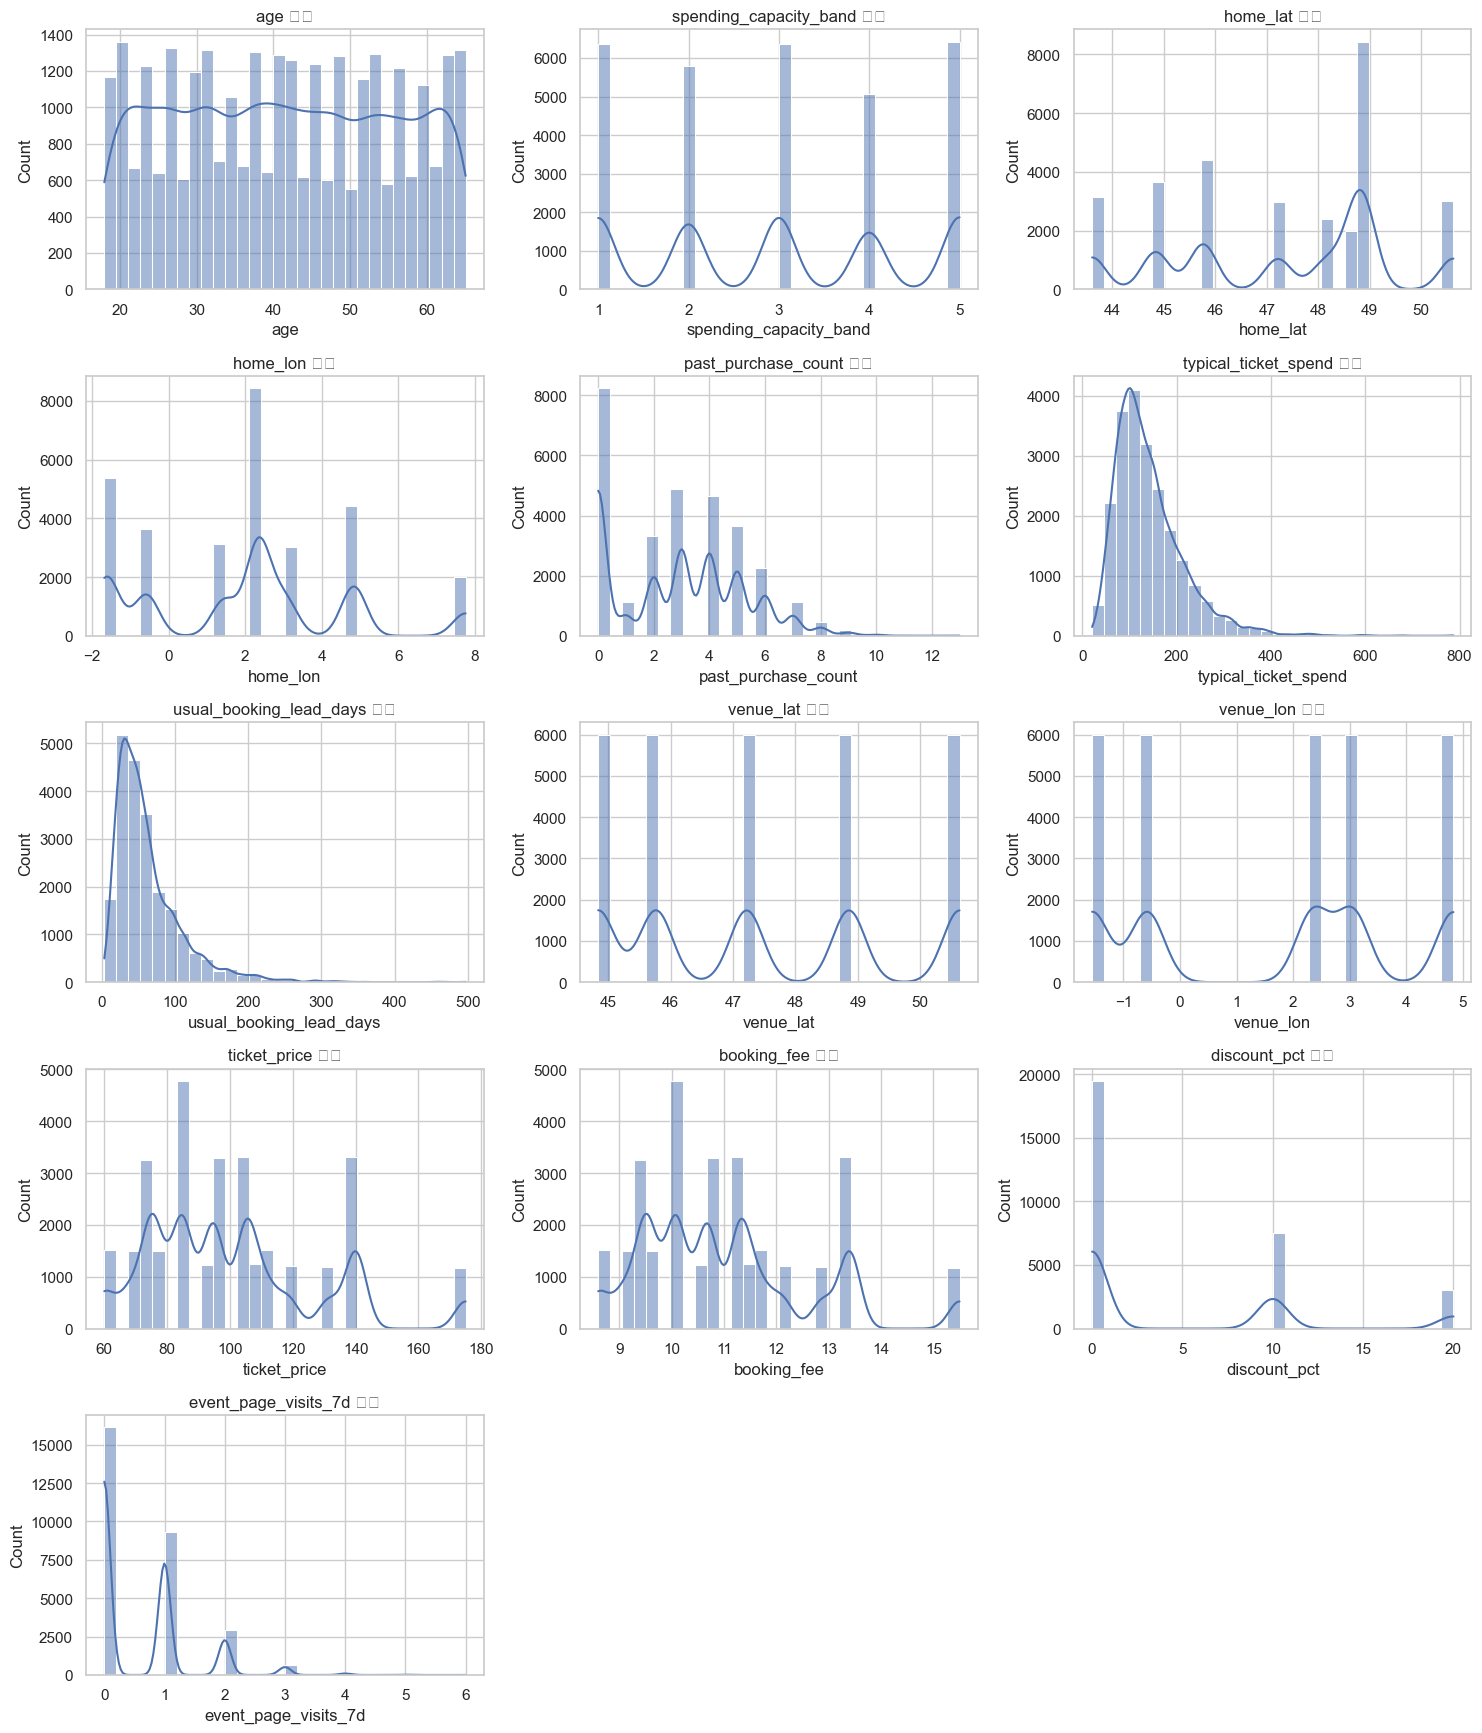

In [26]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

plot_numeric = [
    c for c in numeric_cols
    if c != "buy" and df[c].nunique(dropna=True) > 2
]

if plot_numeric:
    display(
        df[plot_numeric]
        .describe(percentiles=[.01, .05, .25, .5, .75, .95, .99])
        .T
    )

    ncols = 3
    nrows = int(np.ceil(len(plot_numeric) / ncols))
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(15, 3.5 * nrows), squeeze=False
    )
    axes = axes.ravel()

    for ax, col in zip(axes, plot_numeric):
        values = df[col].dropna()
        unique_values = sorted(values.unique())

        if len(unique_values) <= 20:
        # Discrete variables: bars have no gaps, and a line connects the frequencies of each value.
            counts = values.value_counts().reindex(unique_values, fill_value=0)
            positions = np.arange(len(unique_values))
            ax.bar(positions, counts.values, width=1.0, align="center")
            ax.plot(positions, counts.values, marker="o", color="darkred")
            ax.set_xticks(positions)
            ax.set_xticklabels([str(v) for v in unique_values], rotation=45)
            ax.set_title(f"{col} 分布（离散变量）")
            ax.set_xlabel(col)
            ax.set_ylabel("Count")

        else:
        # Continuous variables: Histogram + KDE
            sns.histplot(data=df, x=col, kde=True, bins=30, ax=ax)
            ax.set_title(f"{col} 分布（连续变量）")

    for ax in axes[len(plot_numeric):]:
        ax.remove()

    plt.tight_layout()
    plt.show()

## 8. Categorical Features: Frequencies and Rare Categories

For categorical fields, first examine the number of samples in each category. If a category has very few samples, using one-hot encoding directly may lead to instability; in such cases, consider merging rare categories or employing models capable of handling categorical variables. The `genres` field, which uses vertical bars as delimiters, is a multi-label field; it can be broken down into multiple 0/1 indicator variables.

In [29]:
categorical_cols = df.select_dtypes(include=["object", "category"]).columns.tolist()
for col in categorical_cols:
    print(f"\n--- {col} | unique value {df[col].nunique(dropna=True)} ---")
    display(df[col].value_counts(dropna=False).head(15).rename("count").to_frame())


--- row_id | unique value 30000 ---


,count
row_id,
R2F019957,1
R0AFEFBFC,1
R03495BDA,1
R1D8625C5,1
R10A4B8E7,1
R0CA11653,1
R1996A0D2,1
R0E02018D,1
R23B2FB2B,1



--- user_id | unique value 6000 ---


,count
user_id,
U2CFDCAAD,5
U13777431,5
U2412BA09,5
U07087DF3,5
U224AB30C,5
U29FAE98B,5
U0CEB089E,5
U2C4FA292,5
U01EF0D68,5



--- music_app_user_id | unique value 5661 ---


,count
music_app_user_id,
NaN,1695
M1B01D2D7,5
M1DB18815,5
M220D70D2,5
M1176E85E,5
M31C4D962,5
M178C4B78,5
M1689A214,5
M2FAE26B3,5


... (14 outputs left out)


--- venue_city | unique value 5 ---


,count
venue_city,
Lille,6000
Lyon,6000
Bordeaux,6000
Paris,6000
Nantes,6000



--- travel_search_city | unique value 8 ---


,count
travel_search_city,
NaN,22496
Lyon,1268
Lille,1237
Paris,1193
Bordeaux,1190
Nantes,1179
Rennes,493
Strasbourg,476
Toulouse,468


## 9. Categorical Features and Purchase Rates

Calculating the mean of `buy` for each category yields the empirical purchase rate for that subgroup. The charts display only those categories with a sufficient number of observations, preventing potential misinterpretation caused by very small groups. While differences in purchase rates can help in formulating hypotheses about features, they do not imply that a specific variable is the cause of a purchase.


concert_id：


,rows,buy_rate
concert_id,,
C03,6000,38.82%
C05,6000,36.47%
C01,6000,32.92%
C02,6000,31.67%
C04,6000,28.23%


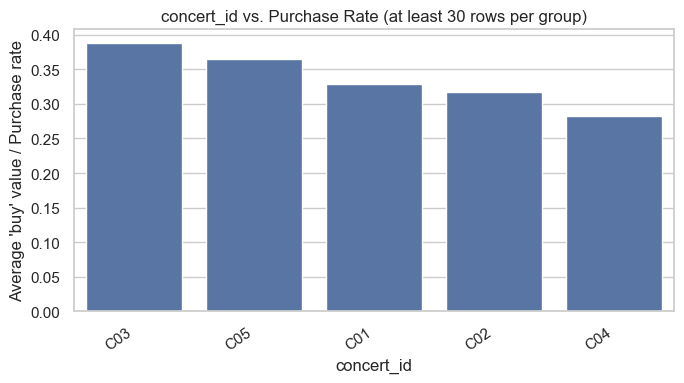


artist_name：


,rows,buy_rate
artist_name,,
Taylor Swift,6000,38.82%
SZA,6000,36.47%
Kendrick Lamar,6000,32.92%
Olivia Rodrigo,6000,31.67%
Tame Impala,6000,28.23%


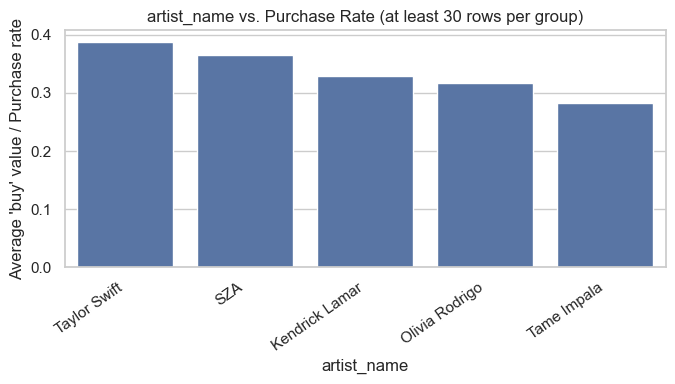


venue_city：


,rows,buy_rate
venue_city,,
Bordeaux,6000,38.82%
Nantes,6000,36.47%
Paris,6000,32.92%
Lyon,6000,31.67%
Lille,6000,28.23%


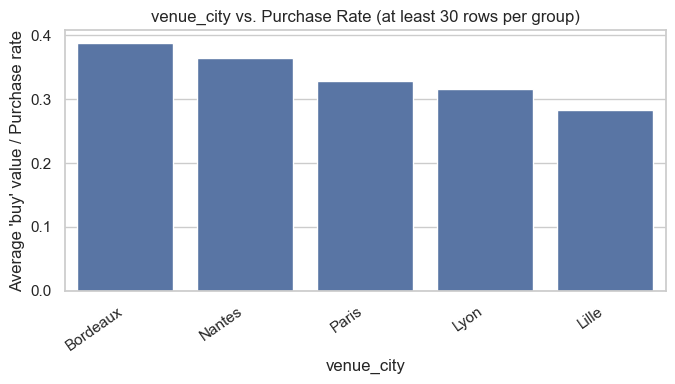


home_city：


,rows,buy_rate
home_city,,
Rennes,2395,36.20%
Nantes,2970,35.12%
Paris,8430,34.21%
Lyon,4410,33.97%
Bordeaux,3650,33.53%
Lille,3015,32.24%
Toulouse,3130,31.44%
Strasbourg,2000,30.70%


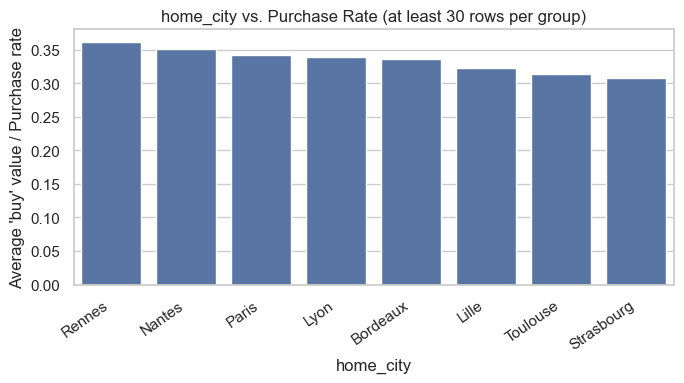


education：


,rows,buy_rate
education,,
postgraduate,6865,34.14%
undergraduate,13190,33.65%
secondary,9945,33.22%


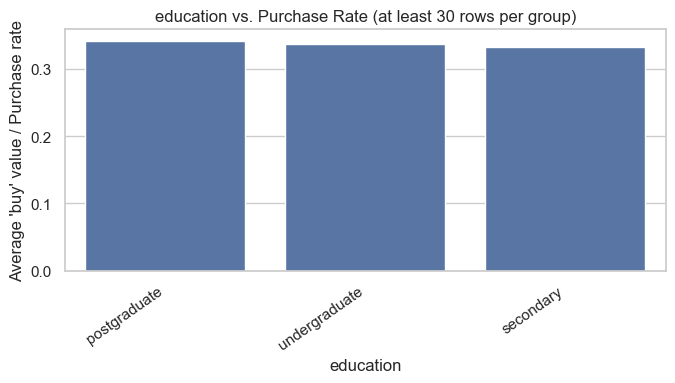


stated_favourite_genre：


,rows,buy_rate
stated_favourite_genre,,
pop,2330,40.56%
rnb_soul,2395,36.49%
pop_rock,2235,34.72%
nan,4625,34.57%
hip_hop,2485,34.25%
alternative,2480,33.71%
folk_country,2370,33.59%
jazz_funk,2320,32.28%
electronic,2255,31.84%


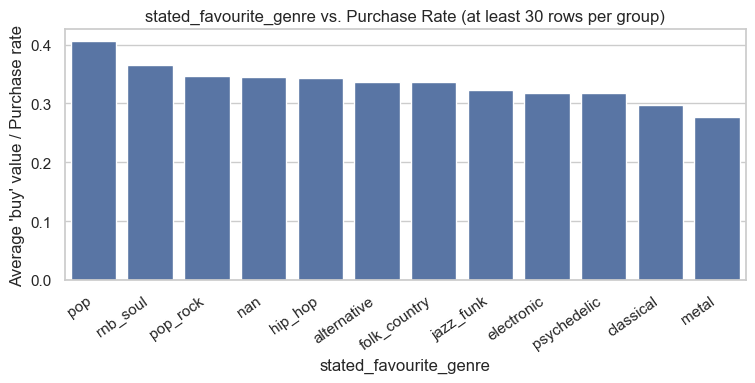


spending_capacity_band：


,rows,buy_rate
spending_capacity_band,,
5,6420,40.55%
4,5055,37.84%
3,6370,34.55%
2,5795,30.84%
1,6360,24.87%


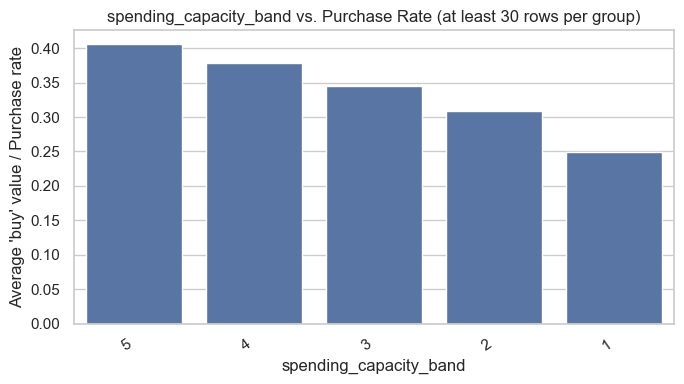


wishlisted：


,rows,buy_rate
wishlisted,,
1,4866,42.70%
0,25134,31.86%


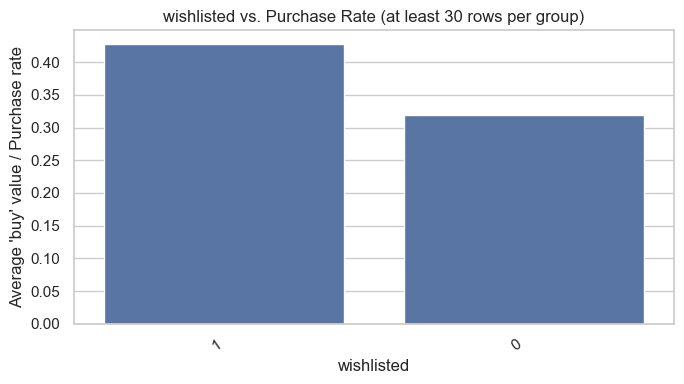


first_timer：


,rows,buy_rate
first_timer,,
1,8240,36.69%
0,21760,32.46%


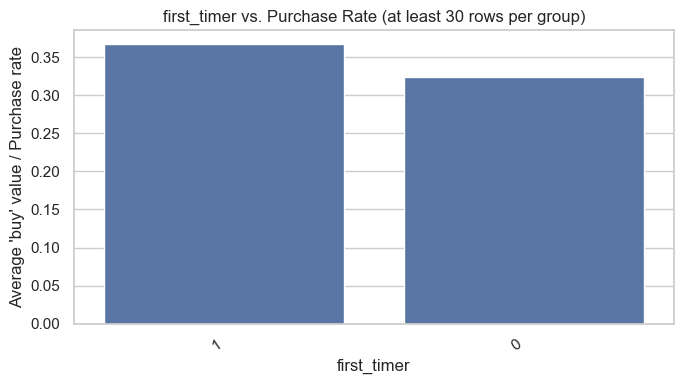

In [31]:
if "buy" in df:
    cat_candidates = [c for c in ["concert_id", "artist_name", "venue_city", "home_city", "education", "stated_favourite_genre", "spending_capacity_band", "wishlisted", "first_timer"] if c in df]
    for col in cat_candidates:
        summary = df.groupby(col, dropna=False).agg(rows=("buy", "size"), buy_rate=("buy", "mean")).query("rows >= 30").sort_values("buy_rate", ascending=False)
        print(f"\n{col}：")
        display(summary.style.format({"buy_rate": "{:.2%}"}))
        if len(summary):
            plt.figure(figsize=(max(7, min(14, 0.65 * len(summary))), 4))
            sns.barplot(x=summary.index.astype(str), y=summary["buy_rate"], color="#4C72B0")
            plt.title(f"{col} vs. Purchase Rate (at least 30 rows per group)")
            plt.ylabel("Average 'buy' value / Purchase rate")
            plt.xlabel(col)
            plt.xticks(rotation=35, ha="right")
            plt.tight_layout()
            plt.show()

## 10. Numerical Features and the Target Variable

To compare the distributions of numerical features between buyers and non-buyers, you can use box plots or violin plots. Since differences in means can be influenced by skewness and extreme values, it is also important to examine medians, quantiles, and sample sizes.

buy                                        0             1
age                     count   19914.000000  10086.000000
                        mean       41.339711     41.538866
                        median     41.000000     41.000000
                        std        13.891620     13.869139
spending_capacity_band  count   19914.000000  10086.000000
                        mean        2.859998      3.214951
                        median      3.000000      3.000000
                        std         1.437348      1.407325
past_purchase_count     count   19914.000000  10086.000000
                        mean        2.946319      2.796649
                        median      3.000000      3.000000
                        std         2.312041      2.333816
typical_ticket_spend    count   14697.000000   7063.000000
                        mean      132.133561    160.717974
                        median    115.270000    147.180000
                        std        69.958588     74.422048
usual_booking_lead_days count   14697.000000   7063.000000
                        mean       63.309859     61.461135
                        median     50.000000     50.500000
                        std        47.587689     43.750794
ticket_price            count   19914.000000  10086.000000
                        mean       99.704052    100.544492
                        median     95.000000     95.000000
                        std        27.099901     26.962309
booking_fee             count   19914.000000  10086.000000
                        mean       10.982247     11.032657
                        median     10.700000     10.700000
                        std         1.626205      1.617870
discount_pct            count   19914.000000  10086.000000
                        mean        4.370292      4.859211
                        median      0.000000      0.000000
                        std         6.624846      6.904333
event_page_visits_7d    count   19317.000000   9820.000000
                        mean        0.539887      0.737780
                        median      0.000000      1.000000
                        std         0.754105      0.864821

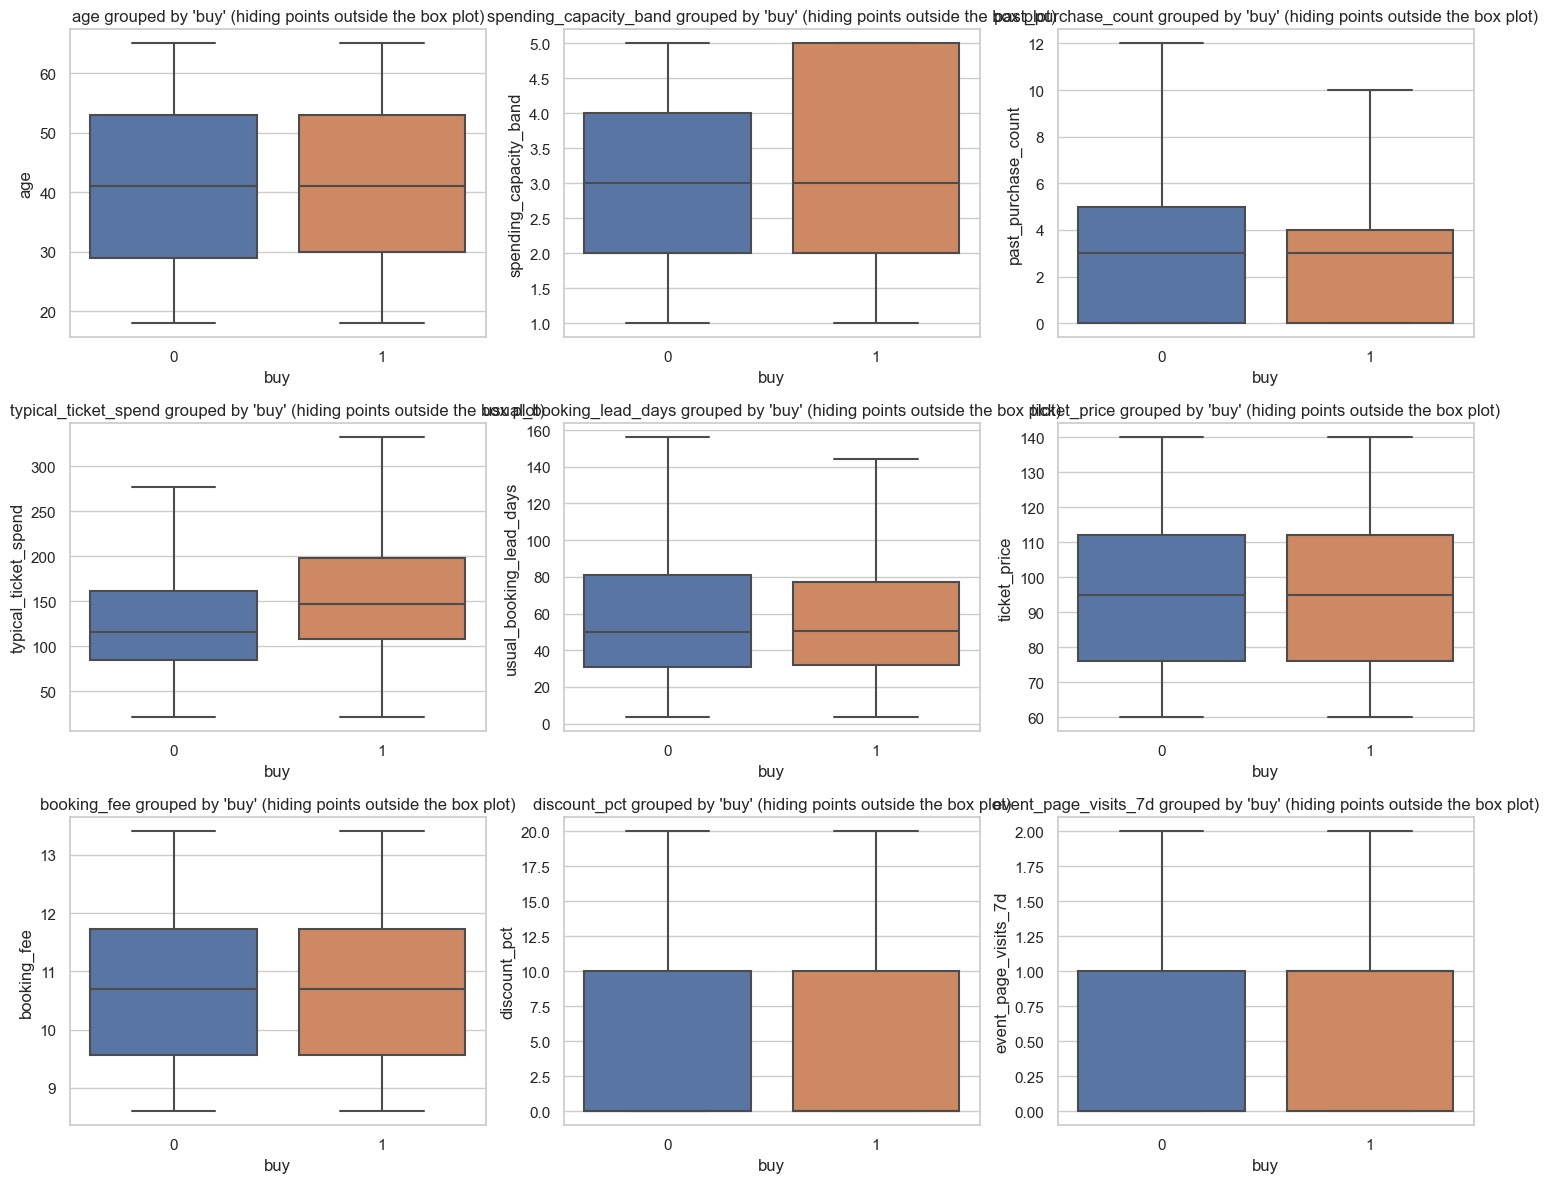

In [33]:
target_numeric = [c for c in ["age", "spending_capacity_band", "past_purchase_count", "typical_ticket_spend", "usual_booking_lead_days", "ticket_price", "booking_fee", "discount_pct", "event_page_visits_7d"] if c in df]
if target_numeric and "buy" in df:
    display(df.groupby("buy")[target_numeric].agg(["count", "mean", "median", "std"]).T)
    ncols = 3
    nrows = int(np.ceil(len(target_numeric) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, target_numeric):
        sns.boxplot(data=df, x="buy", y=col, showfliers=False, ax=ax)
        ax.set_title(f"{col} grouped by 'buy' (hiding points outside the box plot)")
    for ax in axes[len(target_numeric):]:
        ax.remove()
    plt.tight_layout()
    plt.show()

## 11. Analyzing Purchase Rates via Binning of Continuous Variables

By partitioning a continuous variable into several groups based on quantiles, one can observe whether a monotonic or non-linear relationship exists. For instance, the impact of price may not be linear, and the number of page visits might exhibit a saturation effect. Binning plots are intended for exploratory analysis; the original continuous values ​​can be retained for formal modeling.


age Quantile Binning:


,rows,buy_rate
age,,
"(17.999, 27.0]",6380,33.20%
"(27.0, 37.0]",6140,33.26%
"(37.0, 46.0]",5770,34.14%
"(46.0, 56.0]",6100,33.39%
"(56.0, 65.0]",5610,34.21%


C:\Users\86135\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\86135\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


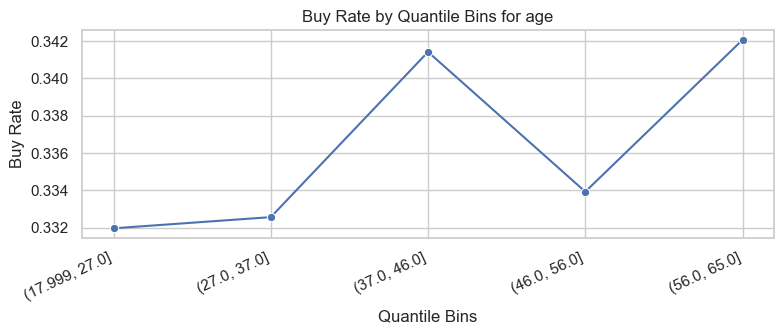


ticket_price Quantile Binning:


,rows,buy_rate
ticket_price,,
"(59.999, 75.0]",6262,30.28%
"(75.0, 85.0]",6279,35.77%
"(85.0, 105.0]",7831,32.61%
"(105.0, 118.75]",3957,36.54%
"(118.75, 175.0]",5671,34.28%


C:\Users\86135\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\86135\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


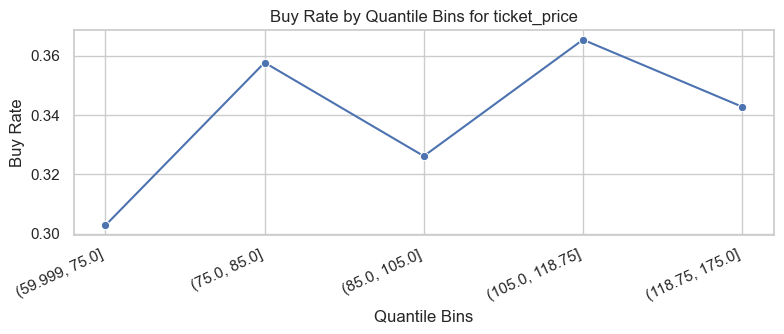


event_page_visits_7d Quantile Binning:


,rows,buy_rate
event_page_visits_7d,,
"(-0.001, 1.0]",25433,32.06%
"(1.0, 6.0]",3704,44.95%


C:\Users\86135\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\86135\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


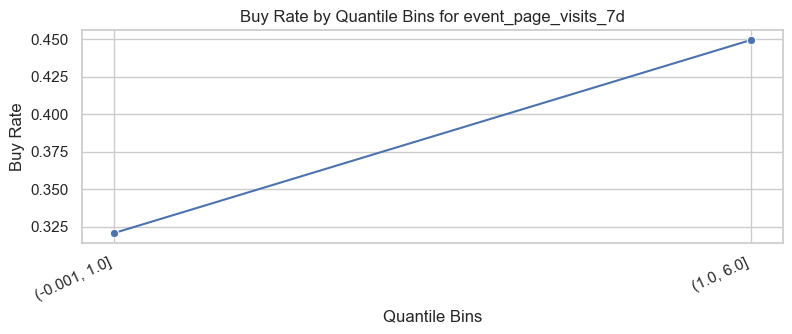


past_purchase_count Quantile Binning:


,rows,buy_rate
past_purchase_count,,
"(-0.001, 2.0]",12695,34.87%
"(2.0, 4.0]",9555,33.00%
"(4.0, 5.0]",3640,32.12%
"(5.0, 13.0]",4110,32.53%


C:\Users\86135\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\86135\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


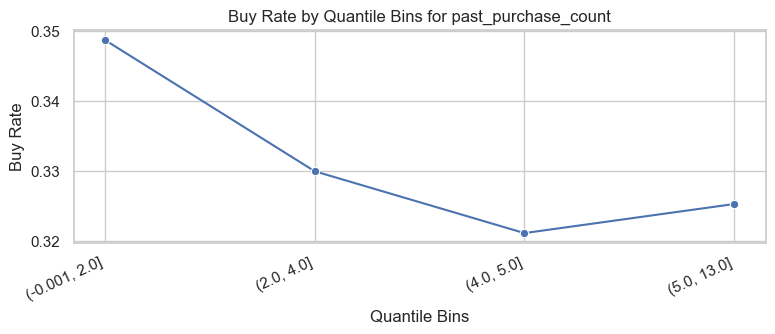


usual_booking_lead_days Quantile Binning:


,rows,buy_rate
usual_booking_lead_days,,
"(3.499, 28.0]",4400,30.68%
"(28.0, 42.0]",4305,32.92%
"(42.0, 59.0]",4420,34.10%
"(59.0, 90.0]",4300,34.40%
"(90.0, 497.0]",4335,30.22%


C:\Users\86135\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\86135\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


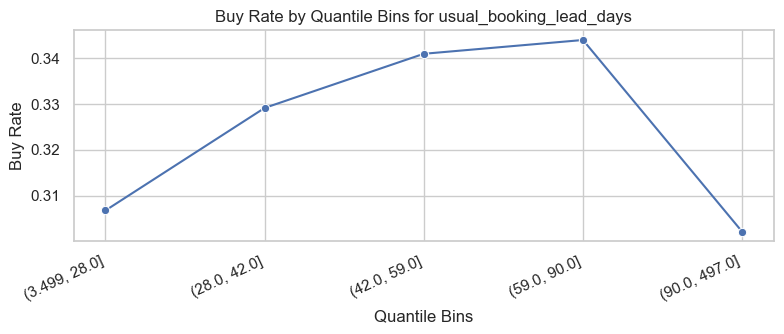

In [35]:
bin_cols = [c for c in ["age", "ticket_price", "event_page_visits_7d", "past_purchase_count", "usual_booking_lead_days"] if c in df]
if "buy" in df:
    for col in bin_cols:
        valid = df[[col, "buy"]].dropna()
        if valid[col].nunique() >= 3:
            try:
                bins = pd.qcut(valid[col], q=min(5, valid[col].nunique()), duplicates="drop")
                summary = valid.groupby(bins, observed=False)["buy"].agg(["size", "mean"])
                print(f"\n{col} Quantile Binning:")
                display(summary.rename(columns={"size": "rows", "mean": "buy_rate"}).style.format({"buy_rate": "{:.2%}"}))
                plt.figure(figsize=(8, 3.5))
                sns.lineplot(x=np.arange(len(summary)), y=summary["mean"].values, marker="o")
                plt.xticks(np.arange(len(summary)), summary.index.astype(str), rotation=25, ha="right")
                plt.title(f"Buy Rate by Quantile Bins for {col}")
                plt.ylabel("Buy Rate")
                plt.xlabel("Quantile Bins")
                plt.tight_layout()
                plt.show()
            except ValueError as e:
                print(f"Could not bin {col}: {e}")

## 12. Correlation Between Numerical Features

Correlation coefficients measure linear relationships and do not imply causation; furthermore, they are not fully adequate for categorical variables, non-linear relationships, or grouped structures. Distances can be derived from `home_lat`, `home_lon`, and venue coordinates—a representation that is generally more interpretable than raw latitude and longitude values.

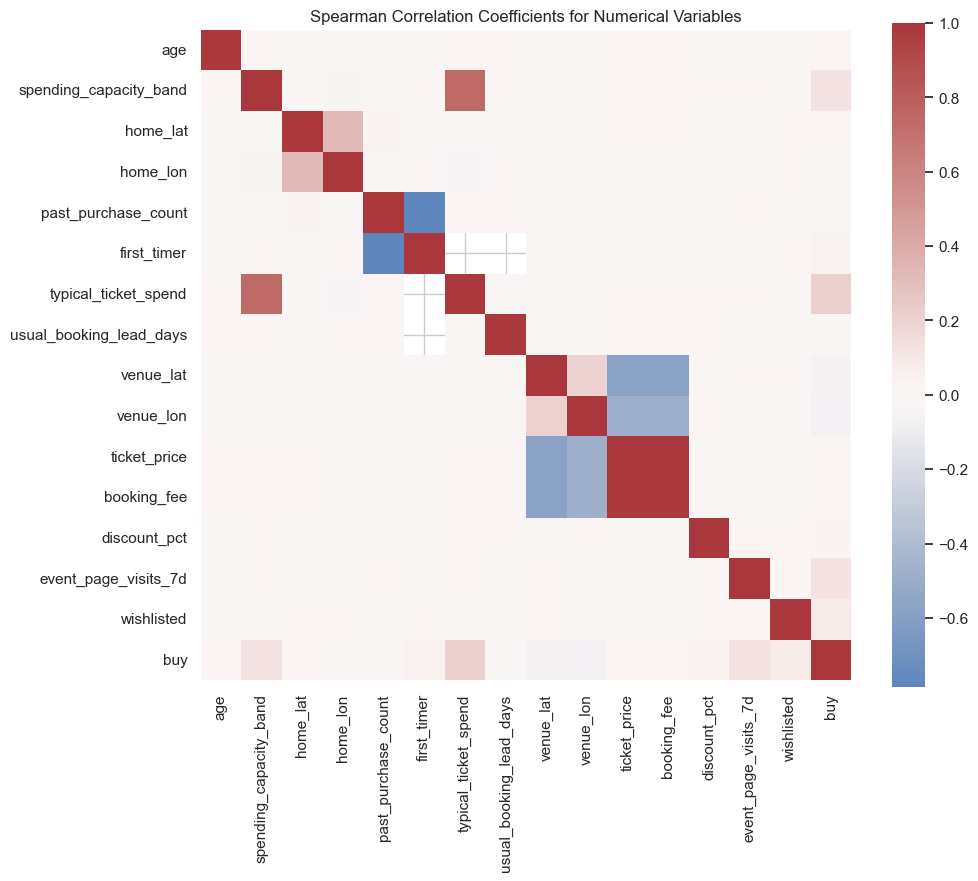

In [36]:
corr_cols = [c for c in df.select_dtypes(include=np.number).columns if df[c].nunique(dropna=True) > 1]
if corr_cols:
    corr = df[corr_cols].corr(method="spearman")
    plt.figure(figsize=(max(9, 0.65 * len(corr_cols)), max(7, 0.55 * len(corr_cols))))
    sns.heatmap(corr, cmap="vlag", center=0, annot=(len(corr_cols) <= 14), fmt=".2f", square=True)
    plt.title("Spearman Correlation Coefficients for Numerical Variables")
    plt.tight_layout()
    plt.show()

## 13. Feature Engineering Examples: Distance, Date, and Price

The following demonstrates how to derive more interpretable variables from existing fields. Distance is approximated using the Haversine formula (great-circle distance). Total fare is calculated as the discounted fare plus the booking fee—please verify this against the discount definitions provided in the assignment's data dictionary. If the discount rules apply differently (e.g., to the total price or specific fees), the formula should be adjusted accordingly.

,count,mean,std,min,25%,50%,75%,max
home_to_venue_km,30000.0,369.347554,209.456788,0.000000,211.686575,391.519646,507.182884,790.678853
estimated_total_price,30000.0,106.459234,28.336127,56.600000,85.560000,104.370000,118.995000,190.500000
days_until_concert,30000.0,56.833333,22.627794,24.833333,40.833333,56.833333,72.833333,88.833333
same_city,30000.0,0.149833,0.356914,0.000000,0.000000,0.000000,0.000000,1.000000


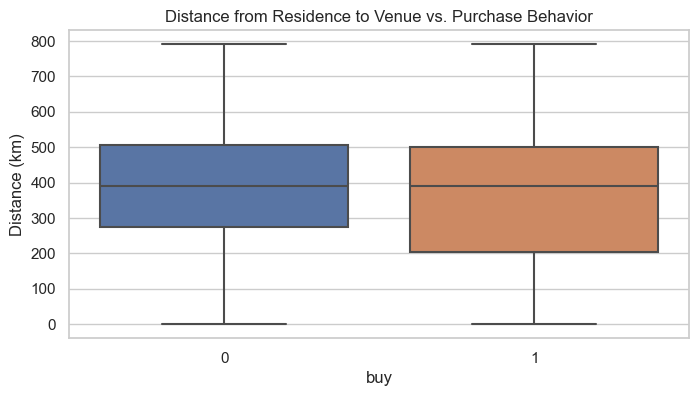

In [37]:
# Haversine: Spherical distance between two sets of latitude and longitude coordinates (in degrees), measured in km
def haversine_km(lat1, lon1, lat2, lon2):
    earth_radius_km = 6371.0
    lat1, lon1, lat2, lon2 = [np.radians(x) for x in (lat1, lon1, lat2, lon2)]
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    return 2 * earth_radius_km * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

if {"home_lat", "home_lon", "venue_lat", "venue_lon"}.issubset(df.columns):
    df["home_to_venue_km"] = haversine_km(df["home_lat"], df["home_lon"], df["venue_lat"], df["venue_lon"])

if {"ticket_price", "booking_fee", "discount_pct"}.issubset(df.columns):
    df["estimated_total_price"] = df["ticket_price"] * (1 - df["discount_pct"] / 100) + df["booking_fee"]

if {"concert_at", "prediction_at"}.issubset(df.columns):
    df["days_until_concert"] = (df["concert_at"] - df["prediction_at"]).dt.total_seconds() / 86400

if {"home_city", "venue_city"}.issubset(df.columns):
    df["same_city"] = (df["home_city"] == df["venue_city"]).astype("int8")

engineered = [c for c in ["home_to_venue_km", "estimated_total_price", "days_until_concert", "same_city"] if c in df]
display(df[engineered].describe().T if engineered else "Insufficient fields available to generate example features.")
if "home_to_venue_km" in df and "buy" in df:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=df, x="buy", y="home_to_venue_km", showfliers=False)
    plt.title("Distance from Residence to Venue vs. Purchase Behavior")
    plt.ylabel("Distance (km)")
    plt.show()

## 14. Reviewing Outliers: Flag, Do Not Automatically Delete

The IQR rule identifies values ​​falling below `Q1 − 1.5 × IQR` or above `Q3 + 1.5 × IQR` as potential outliers. This rule serves merely as a screening tool; it does not imply that such values ​​are necessarily erroneous. For variables with long-tail distributions—such as transaction amounts or the number of days in advance a booking is made—these outliers may well represent genuine behavior.

In [38]:
outlier_rows = []
for col in [c for c in ["age", "typical_ticket_spend", "usual_booking_lead_days", "ticket_price", "event_page_visits_7d", "home_to_venue_km"] if c in df]:
    s = df[col].dropna()
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_rows.append({"feature": col, "lower_fence": lower, "upper_fence": upper, "potential_outlier_count": ((s < lower) | (s > upper)).sum(), "potential_outlier_pct": ((s < lower) | (s > upper)).mean() * 100})
display(pd.DataFrame(outlier_rows).set_index("feature").style.format({"lower_fence": "{:.2f}", "upper_fence": "{:.2f}", "potential_outlier_pct": "{:.2f}%"}))

,lower_fence,upper_fence,potential_outlier_count,potential_outlier_pct
feature,,,,
age,-4.50,87.50,0,0.00%
typical_ticket_spend,-35.73,302.04,770,3.54%
usual_booking_lead_days,-39.75,150.25,1155,5.31%
ticket_price,22.00,166.00,1178,3.93%
event_page_visits_7d,-1.50,2.50,796,2.73%
home_to_venue_km,-231.56,950.43,0,0.00%


## 15. Example of User-Grouped Validation (Preventing Data Leakage)

The following code demonstrates how to perform the data split; it does not include model training. `GroupShuffleSplit` ensures that the same `user_id` does not appear in both the training and validation folds. In an actual competition, you could further employ `GroupKFold` for multi-fold evaluation. The F1 score for the validation set should be calculated by aggregating all validation rows—as required by the problem specifications—and the classification threshold should be tuned based on the validation set.

In [39]:
from sklearn.model_selection import GroupShuffleSplit

if {"user_id", "buy"}.issubset(df.columns):
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    train_idx, valid_idx = next(splitter.split(df, df["buy"], groups=df["user_id"]))
    train_part, valid_part = df.iloc[train_idx], df.iloc[valid_idx]
    train_users, valid_users = set(train_part["user_id"]), set(valid_part["user_id"])
    print(f"Training: {len(train_part):,} rows, {train_part['user_id'].nunique():,} users, purchase rate {train_part['buy'].mean():.2%}")
    print(f"Validation: {len(valid_part):,} rows, {valid_part['user_id'].nunique():,} users, purchase rate {valid_part['buy'].mean():.2%}")
    print("Intersection of training and validation users:", len(train_users & valid_users))
    assert train_users.isdisjoint(valid_users)

Training: 24,000 rows, 4,800 users, purchase rate 33.43%
Validation: 6,000 rows, 1,200 users, purchase rate 34.37%
Intersection of training and validation users: 0


## 16. Modeling Checklist Post-EDA

1. Use `user_id` for grouping during validation to prevent data leakage. While `row_id` is typically used only for aligning submission files, `user_id` should be used for defining groups rather than as a direct categorical feature.
2. Establish a simple baseline first, then compare models such as Logistic Regression, Random Forests, and Gradient Boosted Trees. Ensure that only information known at the time of the "snapshot" is used for training.
3. Create indicators with business-relevant meaning for missing fields; for instance, distinguish between scenarios such as "first-time purchase," "unlinked account," or "no travel search history."
4. Construct interest-matching features based on user-concert pairs—for example, check if a user’s preferred music genre appears in the concert’s `genres` list. Data from the music-listening JSON can be used to derive features such as artist/genre affinity, the ratio of active playbacks, completion rates, and save/favorite rates.
5. When merging the music-listening JSON data, aggregate it by user first, then join it with the concert records using `user_id`. Verify that the total number of rows remains 30,000 after the join and that each user-concert key is unique.
6. Determine the decision threshold using the pooled F1 score on the validation set. Model-predicted probabilities are not the final submission; the final output must consist of binary (0/1) values.
7. Observe score fluctuations across different random seeds or cross-validation folds to avoid drawing conclusions based on a single data split.

**Note:** Refer to `data_dictionary.md` to confirm the precise definitions of fields—specifically whether variables like `spending_capacity_band` are ordinal, how `discount_pct` is applied, and the origins of various missing values. While you may explore the data freely during the initial phase, always cross-reference the data dictionary before finalizing your model.